# CatBoost

CatBoost can also fit entirely numerical data. Its symmetric trees use the same split condition at each level.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from gallery.tabular import concrete_split, regression_report

model = CatBoostRegressor(
    iterations=160,
    depth=5,
    learning_rate=0.07,
    verbose=False,
    allow_writing_files=False,
    thread_count=1,
    random_seed=17,
)

## Data and split

All ages of a concrete recipe stay in the same partition. Five training folds also keep recipes together. The final test uses unseen mixes.

In [3]:
X, X_test, y, y_test, groups = concrete_split()

## Held-out predictions

The table includes a training-only baseline. Both panels use the untouched test observations.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.867, MAE 4.49 MPa
                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.867      4.625       6.299            3.310                  -1.821
Training mean -0.002     14.236      17.267           13.145                  -0.829


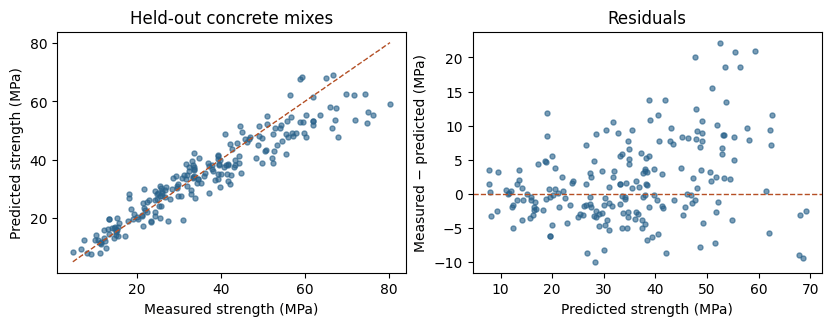

In [4]:
predictions = regression_report(model, X, X_test, y, y_test, groups)
plt.show()

## Reading the result

This dataset measures numerical regression performance. It does not exercise categorical-feature handling.

## References

[Prokhorenkova et al., CatBoost (2018)](https://arxiv.org/abs/1706.09516)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)